In [ ]:
from datasets import load_dataset

ds = load_dataset("eQOURSE/jee-main-questions", data_dir="chemistry")

README.md:   0%|          | 0.00/4.38k [00:00<?, ?B/s]

train.jsonl:   0%|          | 0.00/517k [00:00<?, ?B/s]

test.jsonl:   0%|          | 0.00/86.4k [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

In [ ]:
!pip install -q timm huggingface_hub


In [ ]:


# ============================================================
# 2. IMPORTS
# ============================================================

import os

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms

from torch.utils.data import Dataset, DataLoader

from PIL import Image, ImageChops, ImageOps

import matplotlib.pyplot as plt

import timm

from huggingface_hub import hf_hub_download

from datasets import load_dataset


In [ ]:

# ============================================================
# 3. DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# ============================================================
# 4. SETTINGS
# ============================================================

IMAGE_SIZE = 128
BATCH_SIZE = 16

if device.type == "cpu":
    EPOCHS = 35
else:
    EPOCHS = 45

LEARNING_RATE = 0.0001
NOISE_LEVEL = 0.08

print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Noise level:", NOISE_LEVEL)


# ============================================================
# 5. LOAD eQOURSE CHEMISTRY DATASET
# ============================================================

ds = load_dataset(
    "eQOURSE/jee-main-questions",
    data_dir="chemistry"
)

train_data = ds["train"]

print(
    "\nChemistry training samples:",
    len(train_data)
)


Device: cpu
Image size: 128
Batch size: 16
Epochs: 35
Noise level: 0.08

Chemistry training samples: 627


# IMAGE PREPROCESSING


In [ ]:

# ============================================================
# 6. GET UNIQUE IMAGE REFERENCES
# ============================================================

image_references = []

for item in train_data:

    images = item["question_images"]

    if images is None:
        continue

    if not isinstance(images, list):
        images = [images]

    for img in images:

        if isinstance(img, str):

            image_references.append(img)


# Remove duplicates
image_references = list(
    dict.fromkeys(image_references)
)

print(
    "Unique image references:",
    len(image_references)
)


# ============================================================
# 7. DOWNLOAD ACTUAL IMAGE FILES
# ============================================================

image_paths = []

print("\nLocating Chemistry images...")


for ref in image_references:

    if ref.startswith("chemistry/"):

        repo_path = ref

    else:

        repo_path = "chemistry/" + ref


    try:

        local_path = hf_hub_download(
            repo_id="eQOURSE/jee-main-questions",
            repo_type="dataset",
            filename=repo_path
        )

        image_paths.append(local_path)

    except Exception as e:

        print(
            "Could not load:",
            ref
        )


print(
    "\nActual images available:",
    len(image_paths)
)


if len(image_paths) == 0:

    raise RuntimeError(
        "No Chemistry images were loaded."
    )


# ============================================================
# 8. IMAGE PREPROCESSING
# ============================================================

def crop_content(image):

    image = image.convert("L")

    background = Image.new(
        "L",
        image.size,
        255
    )

    difference = ImageChops.difference(
        image,
        background
    )

    bbox = difference.getbbox()

    if bbox is not None:

        padding = 15

        left = max(
            0,
            bbox[0] - padding
        )

        top = max(
            0,
            bbox[1] - padding
        )

        right = min(
            image.width,
            bbox[2] + padding
        )

        bottom = min(
            image.height,
            bbox[3] + padding
        )

        image = image.crop(
            (
                left,
                top,
                right,
                bottom
            )
        )

    return image


def preprocess_image(path):

    image = Image.open(
        path
    ).convert("L")

    # Crop unnecessary white borders
    image = crop_content(image)

    # Mild contrast enhancement
    image = ImageOps.autocontrast(
        image,
        cutoff=0
    )

    width, height = image.size

    # Make square
    size = max(
        width,
        height
    )

    canvas = Image.new(
        "L",
        (size, size),
        255
    )

    x = (size - width) // 2
    y = (size - height) // 2

    canvas.paste(
        image,
        (x, y)
    )

    # Resize
    image = canvas.resize(
        (IMAGE_SIZE, IMAGE_SIZE),
        Image.Resampling.LANCZOS
    )

    return image


Unique image references: 102

Locating Chemistry images...


chemistry/images/image48.png: reconstructing file:   0%|          |  0.00B / 6.89kB            

chemistry/images/image48.png: downloading bytes:           |  0.00B            

chemistry/images/image10.png: reconstructing file:   0%|          |  0.00B / 21.7kB            

chemistry/images/image10.png: downloading bytes:           |  0.00B            

...

chemistry/images/image29.png: reconstructing file:   0%|          |  0.00B / 2.74kB            

chemistry/images/image29.png: downloading bytes:           |  0.00B            

chemistry/images/image52.png: reconstructing file:   0%|          |  0.00B / 6.92kB            

chemistry/images/image52.png: downloading bytes:           |  0.00B            


Actual images available: 102


In [ ]:
# ============================================================
# 9. DATASET FOR U-NET
# ============================================================

class ChemistryImageDataset(Dataset):

    def __init__(self, paths):

        self.paths = paths

        self.to_tensor = transforms.ToTensor()


    def __len__(self):

        return len(self.paths)


    def __getitem__(self, index):

        image = preprocess_image(
            self.paths[index]
        )

        clean = self.to_tensor(
            image
        )

        # Add small artificial Gaussian noise
        noise = (
            torch.randn_like(clean)
            * NOISE_LEVEL
        )

        noisy = torch.clamp(
            clean + noise,
            0,
            1
        )

        return noisy, clean


dataset = ChemistryImageDataset(
    image_paths
)

loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

print(
    "U-Net training images:",
    len(dataset)
)


U-Net training images: 102


# UNET ARCHITECTURE


U-Net created.

Training U-Net...

Epoch 01/35 | Loss: 0.024690
Epoch 02/35 | Loss: 0.011979
Epoch 03/35 | Loss: 0.005044
Epoch 04/35 | Loss: 0.005315
Epoch 05/35 | Loss: 0.004041
Epoch 06/35 | Loss: 0.003891
Epoch 07/35 | Loss: 0.003609
Epoch 08/35 | Loss: 0.003332
Epoch 09/35 | Loss: 0.003139
Epoch 10/35 | Loss: 0.002910
Epoch 11/35 | Loss: 0.002740
Epoch 12/35 | Loss: 0.002614
Epoch 13/35 | Loss: 0.002581
Epoch 14/35 | Loss: 0.002521
Epoch 15/35 | Loss: 0.002407
Epoch 16/35 | Loss: 0.002373
Epoch 17/35 | Loss: 0.002286
Epoch 18/35 | Loss: 0.002256
Epoch 19/35 | Loss: 0.002305
Epoch 20/35 | Loss: 0.002181
Epoch 21/35 | Loss: 0.002148
Epoch 22/35 | Loss: 0.002148
Epoch 23/35 | Loss: 0.002179
Epoch 24/35 | Loss: 0.002140
Epoch 25/35 | Loss: 0.002090
Epoch 26/35 | Loss: 0.002092
Epoch 27/35 | Loss: 0.002110
Epoch 28/35 | Loss: 0.002078
Epoch 29/35 | Loss: 0.002101
Epoch 30/35 | Loss: 0.002056
Epoch 31/35 | Loss: 0.002069
Epoch 32/35 | Loss: 0.001991
Epoch 33/35 | Loss: 0.002049
Epoch 3

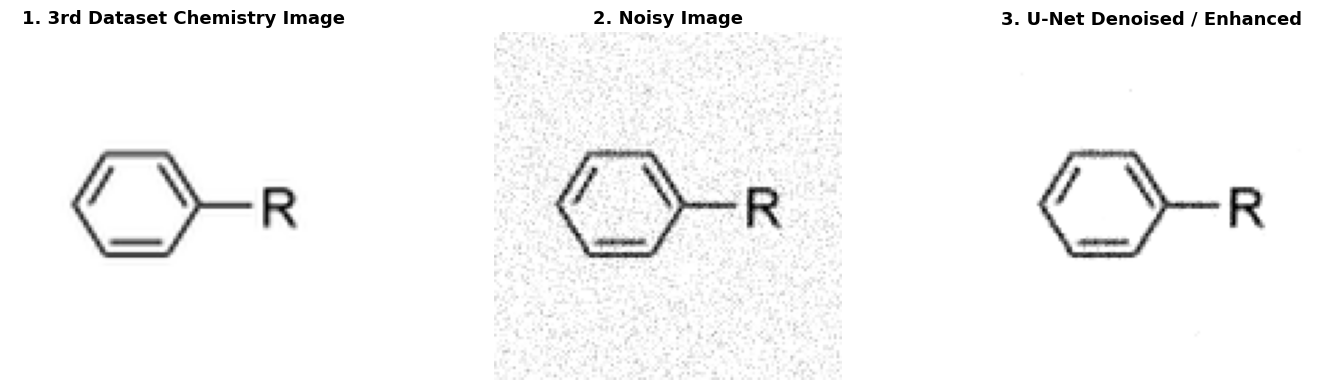

 dataset image:
/root/.cache/huggingface/hub/datasets--eQOURSE--jee-main-questions/snapshots/16ebe036e04dfffffc0ae42717bf4fd5c0d25cf3/chemistry/images/image41.png


In [ ]:
# ============================================================
# 10. U-NET
# ============================================================

class DoubleConv(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels
    ):

        super().__init__()

        self.block = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                3,
                padding=1
            ),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                3,
                padding=1
            ),

            nn.ReLU(inplace=True)
        )


    def forward(self, x):

        return self.block(x)


class UNet(nn.Module):

    def __init__(self):

        super().__init__()

        # -----------------------------
        # Encoder
        # -----------------------------

        self.enc1 = DoubleConv(
            1,
            64
        )

        self.enc2 = DoubleConv(
            64,
            128
        )

        self.enc3 = DoubleConv(
            128,
            256
        )

        self.pool = nn.MaxPool2d(2)

        # -----------------------------
        # Bottleneck
        # -----------------------------

        self.bottleneck = DoubleConv(
            256,
            512
        )

        # -----------------------------
        # Decoder
        # -----------------------------

        self.up3 = nn.ConvTranspose2d(
            512,
            256,
            2,
            stride=2
        )

        self.dec3 = DoubleConv(
            512,
            256
        )

        self.up2 = nn.ConvTranspose2d(
            256,
            128,
            2,
            stride=2
        )

        self.dec2 = DoubleConv(
            256,
            128
        )

        self.up1 = nn.ConvTranspose2d(
            128,
            64,
            2,
            stride=2
        )

        self.dec1 = DoubleConv(
            128,
            64
        )

        # Predict residual/noise correction
        self.residual = nn.Conv2d(
            64,
            1,
            1
        )


    def forward(self, x):

        # -----------------------------
        # Encoder
        # -----------------------------

        e1 = self.enc1(x)

        e2 = self.enc2(
            self.pool(e1)
        )

        e3 = self.enc3(
            self.pool(e2)
        )

        # -----------------------------
        # Bottleneck
        # -----------------------------

        b = self.bottleneck(
            self.pool(e3)
        )

        # -----------------------------
        # Decoder
        # -----------------------------

        d3 = self.up3(b)

        d3 = torch.cat(
            [d3, e3],
            dim=1
        )

        d3 = self.dec3(d3)

        d2 = self.up2(d3)

        d2 = torch.cat(
            [d2, e2],
            dim=1
        )

        d2 = self.dec2(d2)

        d1 = self.up1(d2)

        d1 = torch.cat(
            [d1, e1],
            dim=1
        )

        d1 = self.dec1(d1)

        # -----------------------------
        # Residual denoising
        # -----------------------------

        correction = self.residual(d1)

        # Preserve original image
        output = x + correction

        output = torch.clamp(
            output,
            0,
            1
        )

        return output


unet = UNet().to(device)

print("\nU-Net created.")


# ============================================================
# 11. CHEMISTRY-AWARE WEIGHTED LOSS
# ============================================================

def chemistry_loss(
    output,
    target
):

    # Higher weight for darker chemical pixels
    weight = 1.0 + 4.0 * (
        1.0 - target
    )

    mse = (
        weight *
        (output - target) ** 2
    ).mean()

    # Edge preservation
    output_x = (
        output[:, :, :, 1:]
        - output[:, :, :, :-1]
    )

    target_x = (
        target[:, :, :, 1:]
        - target[:, :, :, :-1]
    )

    output_y = (
        output[:, :, 1:, :]
        - output[:, :, :-1, :]
    )

    target_y = (
        target[:, :, 1:, :]
        - target[:, :, :-1, :]
    )

    edge_loss = (
        F.l1_loss(
            output_x,
            target_x
        )
        +
        F.l1_loss(
            output_y,
            target_y
        )
    )

    return mse + 0.1 * edge_loss


# ============================================================
# 12. TRAIN U-NET
# ============================================================

optimizer = torch.optim.Adam(
    unet.parameters(),
    lr=LEARNING_RATE
)

print("\nTraining U-Net...\n")


for epoch in range(EPOCHS):

    unet.train()

    total_loss = 0.0

    for noisy, clean in loader:

        noisy = noisy.to(device)

        clean = clean.to(device)

        optimizer.zero_grad()

        output = unet(
            noisy
        )

        loss = chemistry_loss(
            output,
            clean
        )

        loss.backward()

        optimizer.step()

        total_loss += loss.item()


    average_loss = (
        total_loss /
        len(loader)
    )

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} "
        f"| Loss: {average_loss:.6f}"
    )


## ============================================================
# 13. THIRD DATASET IMAGE — U-NET RESULT
# ============================================================

unet.eval()

# ------------------------------------------------------------
# Select 15rd Chemistry image from dataset
# ------------------------------------------------------------

third_image = preprocess_image(
    image_paths[16]
)

# Convert to tensor
third_tensor = transforms.ToTensor()(
    third_image
).unsqueeze(0).to(device)


# ============================================================
# CREATE NOISY VERSION
# ============================================================

torch.manual_seed(42)

noise = (
    torch.randn_like(third_tensor)
    * NOISE_LEVEL
)

third_noisy = torch.clamp(
    third_tensor + noise,
    0,
    1
)


# ============================================================
# U-NET DENOISING
# ============================================================

with torch.no_grad():

    third_denoised = unet(
        third_noisy
    )


# ============================================================
# CONVERT TO PIL
# ============================================================

third_clean_pil = transforms.ToPILImage()(
    third_tensor.squeeze(0).cpu()
)

third_noisy_pil = transforms.ToPILImage()(
    third_noisy.squeeze(0).cpu()
)

third_denoised_pil = transforms.ToPILImage()(
    third_denoised.squeeze(0).cpu()
)


# ============================================================
# 14. DISPLAY THIRD DATASET IMAGE
# ============================================================

plt.figure(
    figsize=(15, 4)
)


# ------------------------------------------------------------
# ORIGINAL
# ------------------------------------------------------------

plt.subplot(
    1,
    3,
    1
)

plt.imshow(
    third_clean_pil,
    cmap="gray"
)

plt.title(
    "1. 3rd Dataset Chemistry Image",
    fontsize=13,
    fontweight="bold"
)

plt.axis("off")


# ------------------------------------------------------------
# NOISY
# ------------------------------------------------------------

plt.subplot(
    1,
    3,
    2
)

plt.imshow(
    third_noisy_pil,
    cmap="gray"
)

plt.title(
    "2. Noisy Image",
    fontsize=13,
    fontweight="bold"
)

plt.axis("off")


# ------------------------------------------------------------
# U-NET OUTPUT
# ------------------------------------------------------------

plt.subplot(
    1,
    3,
    3
)

plt.imshow(
    third_denoised_pil,
    cmap="gray"
)

plt.title(
    "3. U-Net Denoised / Enhanced",
    fontsize=13,
    fontweight="bold"
)

plt.axis("off")


plt.tight_layout()

plt.show()


# Show which dataset image was used
print(" dataset image:")
print(image_paths[2])

In [ ]:
# ============================================================
# DOWNLOAD U-NET ENHANCED IMAGES FOLDER
# ============================================================

import shutil
from google.colab import files

folder_path = "/content/unet_enhanced_images"
zip_path = "/content/unet_enhanced_images"

# Create ZIP file from the folder
shutil.make_archive(
    zip_path,
    "zip",
    folder_path
)

# Download ZIP
files.download(
    zip_path + ".zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip install -q timm

Traceback (most recent call last):
  File "/usr/local/bin/pip3", line 4, in <module>
    from pip._internal.cli.main import main
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/cli/main.py", line 11, in <module>
    from pip._internal.cli.autocompletion import autocomplete
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/cli/autocompletion.py", line 10, in <module>
    from pip._internal.cli.main_parser import create_main_parser
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/cli/main_parser.py", line 9, in <module>
    from pip._internal.build_env import get_runnable_pip
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/build_env.py", line 19, in <module>
    from pip._internal.cli.spinners import open_spinner
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/cli/spinners.py", line 9, in <module>
    from pip._internal.utils.logging import get_indentation
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/util

In [ ]:
from google.colab import files
import zipfile
import os

uploaded = files.upload()  # Select generated_question_images.zip

ZIP_PATH = next(iter(uploaded.keys()))
IMAGE_FOLDER = "/content/chemistry_images"

os.makedirs(IMAGE_FOLDER, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(IMAGE_FOLDER)

print("Dataset extracted:", IMAGE_FOLDER)

Saving generated_question_images.zip to generated_question_images (1).zip
Dataset extracted: /content/chemistry_images


# SWIN STAGES

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm
import numpy as np
from PIL import Image
from pathlib import Path
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp", ".webp"}

image_paths = sorted([
    str(p) for p in Path(IMAGE_FOLDER).rglob("*")
    if p.is_file()
    and p.suffix.lower() in IMAGE_EXTENSIONS
    and p.stat().st_size > 0
])

print("Images found:", len(image_paths))

swin = timm.create_model(
    "swin_tiny_patch4_window7_224",
    pretrained=True,
    features_only=True
).to(device)

swin.eval()

for param in swin.parameters():
    param.requires_grad = False

print("Swin stage channels:", swin.feature_info.channels())

Device: cpu
Images found: 2005


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

Swin stage channels: [96, 192, 384, 768]


# MLP HEAD

In [ ]:
class FeatureMLP(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, 128)
        )

    def forward(self, x):
        return self.network(x)


swin_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Infer the final stage's channel count safely.
with torch.no_grad():
    dummy = torch.zeros(1, 3, 224, 224).to(device)
    final_stage = swin(dummy)[-1]

# timm Swin feature maps are commonly NHWC when features_only=True.
# Detect the channel dimension using the model's feature metadata.
channels = swin.feature_info.channels()[-1]

if final_stage.shape[-1] == channels:
    pooled_size = channels
elif final_stage.shape[1] == channels:
    pooled_size = channels
else:
    raise ValueError(f"Unexpected final Swin shape: {final_stage.shape}")

mlp = FeatureMLP(pooled_size).to(device)
mlp.eval()

print("MLP input size:", pooled_size)
print("MLP output size: 128")

MLP input size: 768
MLP output size: 128


In [ ]:
class ChemistryImageDataset(Dataset):
    def __init__(self, paths):
        self.paths = paths

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        path = self.paths[idx]
        try:
            with Image.open(path) as img:
                image = img.convert("RGB")
            return swin_transform(image), path
        except Exception as e:
            raise RuntimeError(f"Could not read {path}: {e}")


dataset = ChemistryImageDataset(image_paths)

loader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

all_features = []
valid_paths = []

with torch.inference_mode():
    for images, paths in tqdm(loader, desc="Swin + MLP"):
        images = images.to(device)

        hierarchy = swin(images)
        final_stage = hierarchy[-1]

        # Convert NHWC to NCHW if needed.
        if final_stage.shape[-1] == swin.feature_info.channels()[-1]:
            final_stage = final_stage.permute(0, 3, 1, 2)

        pooled = F.adaptive_avg_pool2d(
            final_stage, (1, 1)
        ).flatten(1)

        vectors = mlp(pooled)

        all_features.append(vectors.cpu())
        valid_paths.extend(paths)

all_features = torch.cat(all_features, dim=0)

print("Images processed:", len(valid_paths))
print("Feature tensor shape:", tuple(all_features.shape))

Swin + MLP:   0%|          | 0/63 [00:00<?, ?it/s]

Images processed: 2005
Feature tensor shape: (2005, 128)


In [ ]:
FEATURE_FILE = "/content/chemistry_swin_mlp_features.pt"

torch.save({
    "features": all_features,
    "image_paths": valid_paths
}, FEATURE_FILE)

# Also save a CSV with 128 numerical feature columns.
import pandas as pd

feature_array = all_features.numpy()

df = pd.DataFrame(
    feature_array,
    columns=[f"feature_{i:03d}" for i in range(128)]
)
df.insert(0, "image_path", valid_paths)

df.to_csv(
    "/content/chemistry_swin_mlp_features.csv",
    index=False
)

print("Saved:", FEATURE_FILE)
print("Saved CSV: /content/chemistry_swin_mlp_features.csv")


Saved: /content/chemistry_swin_mlp_features.pt
Saved CSV: /content/chemistry_swin_mlp_features.csv


In [ ]:
from google.colab import files

files.download("/content/chemistry_swin_mlp_features.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import torch

data = torch.load(
    "/content/chemistry_swin_mlp_features.pt",
    map_location="cpu",
    weights_only=False
)

features = data["features"]
image_paths = data["image_paths"]

print("Image:", image_paths[0])
print("Feature vector:")
print(features[0].numpy())
print("Shape:", features[0].shape)

Image: /content/chemistry_images/generated_question_images/graph_003.png
Feature vector:
[ 0.15833105 -0.13922909 -0.00286902 -0.47645158 -0.8514996  -0.5365291
  0.12490857  0.16857868 -0.06887785  0.32770422 -0.17410728  0.1712664
  0.07588598 -0.49496344 -0.6164819   0.65094125 -0.09934378  0.3788624
 -0.28773576  0.06765705  0.19438253  0.19936414  0.132458    0.8465177
  0.40220588 -0.07872363 -0.433999    0.3926151  -0.04929432  0.17989591
  0.21700335  0.08774112  0.23952231  0.08647685  0.1465475   0.32839328
  0.3565467  -0.51802105  0.11349469 -0.6075855   0.06937117  0.16214177
  0.4116252  -0.42754608  0.4010986  -0.26781902 -0.12541747  0.55739135
 -0.05728791 -0.88492745 -0.25199184 -0.21393651 -0.17468679  0.4774445
 -0.08126016 -0.3864694  -0.18185496  0.22324106  0.32449627  0.10427342
 -0.25578892 -0.203895   -0.11777253  0.25823328  0.18763164 -0.02309974
 -0.02458098  0.4454251  -0.82880163 -0.28470343  0.3614784  -0.5306461
 -0.66348565  0.03773374 -0.14491378 -0.0

# SWIN FOR A SINGLE IMAGE

Image: /content/chemistry_images/generated_question_images/graph_003.png
Feature vector dimensions: (128,)

128-D Feature Vector:
 [ 0.15833105 -0.13922909 -0.00286902 -0.47645158 -0.8514996  -0.5365291
  0.12490857  0.16857868 -0.06887785  0.32770422 -0.17410728  0.1712664
  0.07588598 -0.49496344 -0.6164819   0.65094125 -0.09934378  0.3788624
 -0.28773576  0.06765705  0.19438253  0.19936414  0.132458    0.8465177
  0.40220588 -0.07872363 -0.433999    0.3926151  -0.04929432  0.17989591
  0.21700335  0.08774112  0.23952231  0.08647685  0.1465475   0.32839328
  0.3565467  -0.51802105  0.11349469 -0.6075855   0.06937117  0.16214177
  0.4116252  -0.42754608  0.4010986  -0.26781902 -0.12541747  0.55739135
 -0.05728791 -0.88492745 -0.25199184 -0.21393651 -0.17468679  0.4774445
 -0.08126016 -0.3864694  -0.18185496  0.22324106  0.32449627  0.10427342
 -0.25578892 -0.203895   -0.11777253  0.25823328  0.18763164 -0.02309974
 -0.02458098  0.4454251  -0.82880163 -0.28470343  0.3614784  -0.5306461

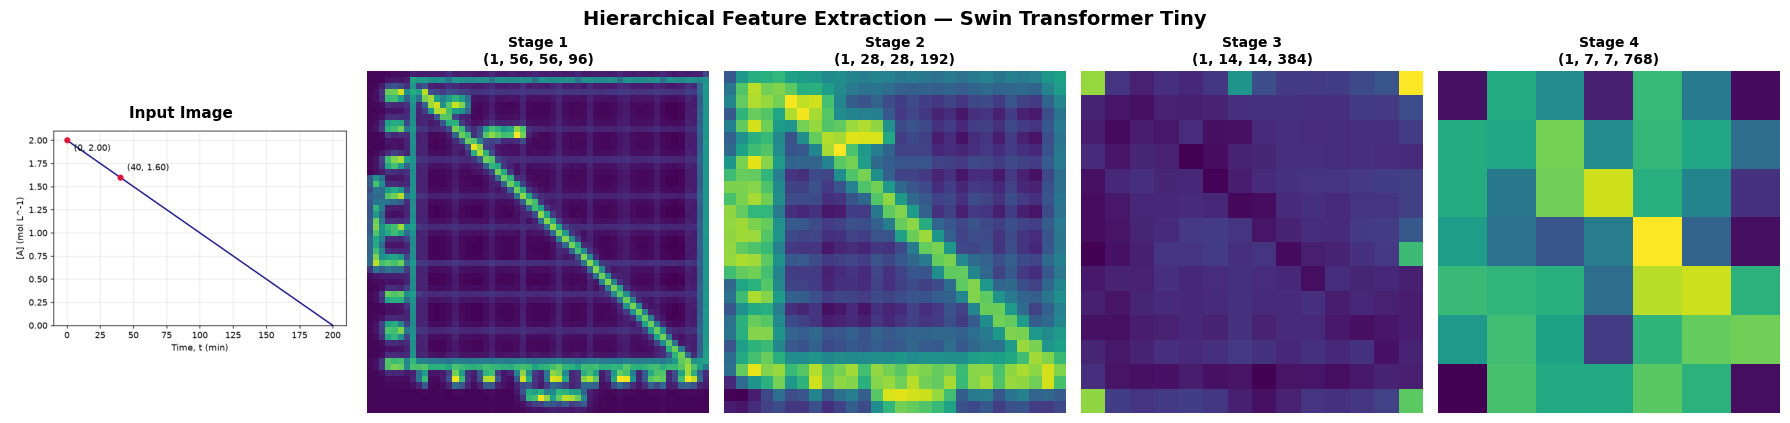

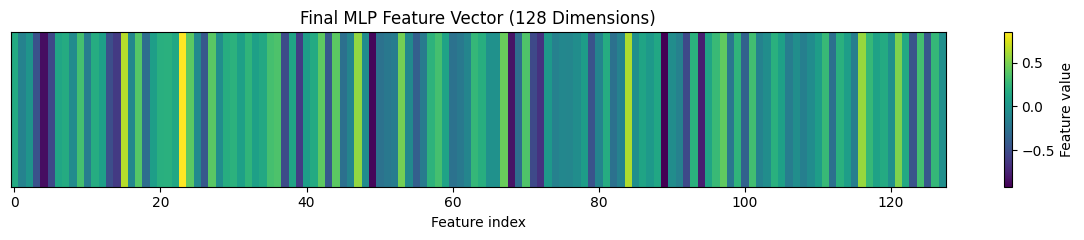

In [ ]:
import torch
import timm
import matplotlib.pyplot as plt
import torch.nn.functional as F
from PIL import Image
from torchvision import transforms

# -------------------------------
# 1. Select image
# -------------------------------
idx = 0  # Change image index here

data = torch.load(
    "/content/chemistry_swin_mlp_features.pt",
    map_location="cpu",
    weights_only=False
)

image_path = data["image_paths"][idx]
vector = data["features"][idx]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Image: {image_path}")
print(f"Feature vector dimensions: {tuple(vector.shape)}")
print("\n128-D Feature Vector:\n", vector.numpy())

# -------------------------------
# 2. Load Swin Transformer
# -------------------------------
swin = timm.create_model(
    "swin_tiny_patch4_window7_224",
    pretrained=True,
    features_only=True
).to(device).eval()

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

original = Image.open(image_path).convert("RGB")
x = transform(original).unsqueeze(0).to(device)

with torch.no_grad():
    stages = swin(x)

# -------------------------------
# 3. Visualize Swin stages
# -------------------------------
fig, axes = plt.subplots(1, 5, figsize=(18, 4.5))

axes[0].imshow(original)
axes[0].set_title("Input Image", fontsize=11, fontweight="bold")
axes[0].axis("off")

channels = swin.feature_info.channels()

for i, feature in enumerate(stages):
    # Convert NHWC to NCHW when necessary
    if feature.shape[-1] == channels[i]:
        feature = feature.permute(0, 3, 1, 2)

    feature_map = feature[0].mean(dim=0).cpu()

    axes[i + 1].imshow(feature_map, cmap="viridis")
    axes[i + 1].set_title(
        f"Stage {i+1}\n{tuple(stages[i].shape)}",
        fontsize=10,
        fontweight="bold"
    )
    axes[i + 1].axis("off")

plt.suptitle(
    "Hierarchical Feature Extraction — Swin Transformer Tiny",
    fontsize=14,
    fontweight="bold"
)
plt.tight_layout()
plt.show()

# -------------------------------
# 4. Display 128-D vector
# -------------------------------
plt.figure(figsize=(12, 2.5))
plt.imshow(vector.numpy().reshape(1, -1), aspect="auto", cmap="viridis")
plt.colorbar(label="Feature value")
plt.title("Final MLP Feature Vector (128 Dimensions)")
plt.xlabel("Feature index")
plt.yticks([])
plt.tight_layout()
plt.show()